# Stress tensor and elasticity equations

This notebook fits a hyperelastic strain energy and its variants to three data sources. 
A hyperelastic material stores all deformation work as elastic energy.
The strain energy function $W(F)$ defines its stress.

## 1. The computational experiment

**Goal.** Identify the parameters of one strain energy family and of its variants from three data sources.
Then compare the parameters across the sources.

In [2]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sympy as sp
from IPython.display import Math, display

from hyperfit import (
    data,
    evaluation,
    experiment,
    graph,
    models,
    parameters,
    plotting,
    sources,
)

plotting.apply_style()
pd.set_option("display.float_format", "{:.4g}".format)
pd.set_option("display.max_colwidth", 80)

CACHE = pathlib.Path("..") / "data" / "raw"
FIGURES = pathlib.Path("..") / "outputs" / "figures"
SRMD = sources.SRMD_ECOFLEX_0030.key
TRELOAR = sources.TRELOAR_1944.key
EUCLID = sources.EUCLID_PLATE_HOLE.key
HOMOGENEOUS_VARIANTS = models.homogeneous_variants()
FIELD_VARIANTS = models.field_variants()

## 2. The governing equation and its variants

**Kinematics.** The displacement $u(X, t)$ moves the material point $X$.

$$F = I + \nabla_X u,\qquad C = F^{\mathsf T}F,\qquad J = \det F,\qquad \bar I_1 = J^{-2/3}\,\operatorname{tr} C .$$

$F$ is the deformation gradient. $C$ is the right Cauchy–Green tensor. $J$ is the volume ratio.
$\bar I_1$ is the isochoric first invariant: a pure volume change does not change it.

**Balance law.** Without inertia and body forces, the balance of linear momentum is

$$\operatorname{Div} P = 0 \ \text{ in } \Omega_0,\qquad P = \frac{\partial W}{\partial F},\qquad u = u_D(t) \ \text{ on } \Gamma_D .$$

$P$ is the first Piola–Kirchhoff stress, a rank-2 tensor: force per undeformed area.
Inertia is negligible in these slow tests, so time enters only through the load history $u_D(t)$.

**Variants of $W$.**

| Variant | Strain energy $W$ | Parameter vector $\theta$ | Sources |
|---|---|---|---|
| Yeoh $N$ (Yeoh 1993) | $\sum_{i=1}^{N} C_{i0}\,(\bar I_1-3)^i$ | $C_{10},\dots,C_{N0}$ | 1, 2 |
| Yeoh $N$ + volumetric | $\sum_{i=1}^{N} C_{i0}\,(\bar I_1-3)^i + D_1\,(J-1)^2$ | $C_{10},\dots,C_{N0},D_1$ | 3 |
| Ogden $M=2$ (Ogden 1972) | $\sum_{p=1}^{2}\frac{\mu_p}{\alpha_p}\left(\lambda_1^{\alpha_p}+\lambda_2^{\alpha_p}+\lambda_3^{\alpha_p}-3\right)$ | $\mu_1,\alpha_1,\mu_2,\alpha_2$ | 1, 2 |

Yeoh $N=1$ is the neo-Hookean model. The Yeoh variants are nested: each order adds one term.
Marechal et al. (2021) fit the neo-Hookean, Yeoh and Ogden models to source 1.
Flaschel et al. (2021) generate source 3 with the neo-Hookean + volumetric variant.

**Homogeneous tests.** In a homogeneous test, $F$ is the same at every point, so $\operatorname{Div} P = 0$ holds automatically.
The stretch $\lambda$ is the deformed length divided by the original length.
The nominal stress follows from the reduced energy $\hat W(\lambda) = W(\lambda_1, \lambda_2, \lambda_3)$:

| Test mode | $(\lambda_1, \lambda_2, \lambda_3)$ | Nominal stress $P$ |
|---|---|---|
| uniaxial | $(\lambda,\ \lambda^{-1/2},\ \lambda^{-1/2})$ | $\mathrm d\hat W/\mathrm d\lambda$ |
| equibiaxial | $(\lambda,\ \lambda,\ \lambda^{-2})$ | $\tfrac12\,\mathrm d\hat W/\mathrm d\lambda$ |
| pure shear | $(\lambda,\ 1,\ \lambda^{-1})$ | $\mathrm d\hat W/\mathrm d\lambda$ |

torch autograd computes every derivative from the expression tree of $W$. No stress formula is written by hand.

**Field test.** Source 3 is a plate with a hole under plane strain ($F_{33} = 1$).
The finite element form of the balance law is the minimum of the total potential energy
$\Pi(u) = \sum_e W(F_e)\,w_e$, where $w_e$ is the element area.
The nodal internal forces are $f = \partial \Pi / \partial u$. Equilibrium means $f = 0$ at every free node.

In [3]:
for variant in HOMOGENEOUS_VARIANTS + FIELD_VARIANTS:
    formula = sp.latex(variant.sympy_expression())
    display(Math(rf"\text{{{variant.title}}}:\quad W = {formula}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 3. Data sources

In [4]:
display(sources.sources_table())
directories = {source.key: data.fetch_source(source, CACHE) for source in sources.ALL_SOURCES}

,title,files,homepage,license,citation
key,,,,,
srmd_ecoflex_00_30,Soft Robotics Materials Database: Ecoflex 00-30 uniaxial test,1,https://github.com/LucMarechal/Soft-Robotics-Materials-Database,Open Database License (ODbL-1.0); contents under DbCL-1.0.,"Marechal, L., Balland, P., Lindenroth, L., Petrou, F., Kontovounisios, C., B..."
treloar_1944,"Treloar (1944) natural rubber: uniaxial, equibiaxial, pure shear",1,https://github.com/LivingMatterLab/CANN,No license file in the repository. Cite the original paper.,"Treloar, L. R. G. (1944). Stress-strain data for vulcanised rubber under var..."
euclid_plate_hole,"EUCLID finite element data: plate with a hole, 4 load steps",16,https://github.com/EUCLID-code/EUCLID-hyperelasticity,GNU General Public License v3.0.,"Flaschel, M., Kumar, S., De Lorenzis, L. (2021). Unsupervised discovery of i..."


In [5]:
srmd_raw = data.srmd_uniaxial_test(directories[SRMD] / "Ecoflex_00-30.csv", SRMD)
srmd_test = data.drop_unloaded_points(
    data.truncate_at_peak_stress(data.rebuild_uniform_time(srmd_raw))
)
treloar_tests = [
    data.drop_unloaded_points(test)
    for test in data.read_treloar_tests(directories[TRELOAR] / "CANNsRUBBERdata.xlsx", TRELOAR)
]
field_steps = data.read_field_steps(directories[EUCLID], sources.EUCLID_LOAD_STEPS)

display(data.homogeneous_summary([srmd_test] + treloar_tests))
display(data.field_summary(field_steps))

,source,material,mode,points,max stretch,max stress,duration [s]
0,srmd_ecoflex_00_30,EcoFlex30,uniaxial,705,17.07,1.359,70.4
1,treloar_1944,"Natural rubber (Treloar 1944, 20 C)",uniaxial,13,7.249,4.49,NaN
2,treloar_1944,"Natural rubber (Treloar 1944, 20 C)",equibiaxial,13,4.451,2.452,NaN
3,treloar_1944,"Natural rubber (Treloar 1944, 20 C)",pure_shear,13,4.989,1.82,NaN


,nodes,elements,free degrees of freedom,max |u|,reactions
load step,,,,,
10,1441,2752,2758,0.1118,"[-0.4786, 0.4786, -0.5446, 0.5446]"
20,1441,2752,2758,0.2236,"[-1.0022, 1.0022, -1.0778, 1.0778]"
30,1441,2752,2758,0.3354,"[-1.454, 1.454, -1.509, 1.509]"
40,1441,2752,2758,0.4621,"[-1.7747, 1.7747, -1.8085, 1.8085]"


**Preprocessing.** Each curve ends at its peak stress, because later points belong to specimen failure.
Points with zero stretch or zero stress drop out, because the relative error is not defined there.
Source 1 converts the engineering strain $\varepsilon$ to the stretch $\lambda = 1 + \varepsilon$.

**Data quality: the time column of source 1.** The raw time column stops increasing at 40.9 s.
It continues with 40.1, 40.11, 40.12 and so on.
The stretch increment per row stays constant at 0.0227 over the full test.
This value matches the crosshead speed: 7.5 mm/s × 0.1 s / 33 mm = 0.0227.
So the sampling interval stays 0.1 s, and `data.rebuild_uniform_time` rebuilds the time from the row index.

**Source 1** is a uniaxial pull-to-failure test of the silicone Ecoflex 00-30 (Smooth-On), a common soft-robot material.
The crosshead moves at a constant speed. So the stretch grows linearly with time.

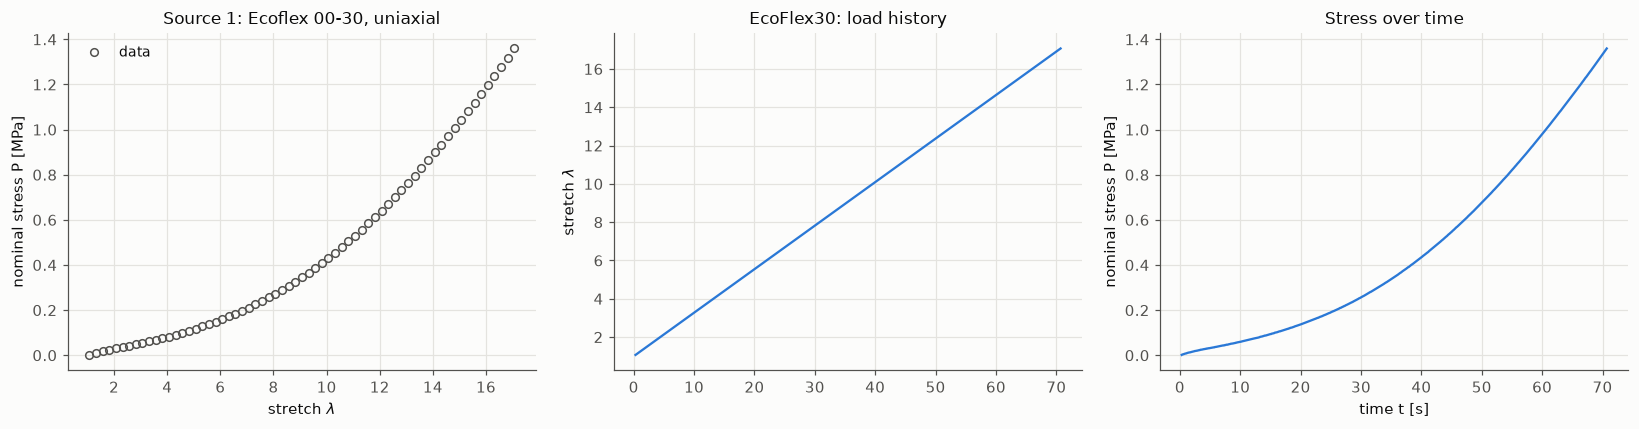

In [ ]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
plotting.plot_test_data(srmd_test, axes[0], "data")
plotting.label_stress_axes(axes[0], "MPa", "Source 1: Ecoflex 00-30, uniaxial")
plotting.plot_time_series(srmd_test, (axes[1], axes[2]))
axes[2].set_title("Stress over time")
figure.tight_layout()
plotting.save_figure(figure, "source1_overview", FIGURES)
plt.show()

The stress–stretch curve is soft at small stretch and stiffens at large stretch.
The test reaches a stretch above 17 after 70 s.
The supplier lists an elongation at break of 900 % (a stretch of 10), so the crosshead strain probably includes grip slip.
A single neo-Hookean term cannot follow this shape.

**Source 2** holds Treloar's classic natural rubber data in three test modes.
Several test modes constrain $W$ better than one mode, because each mode probes a different combination of the stretches.

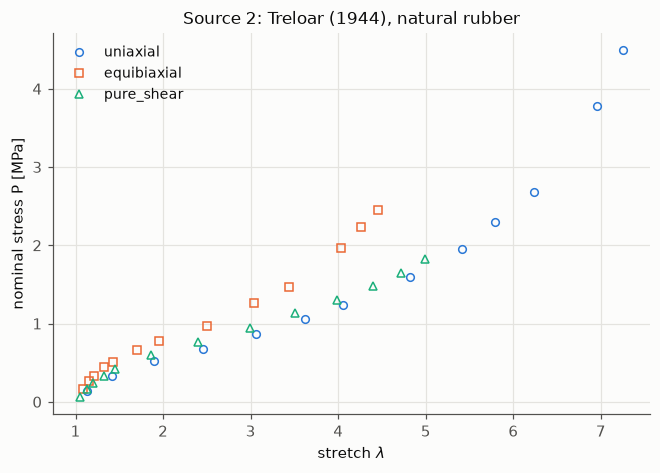

In [ ]:
figure, ax = plt.subplots(figsize=(7, 4.5))
for slot, (test, marker) in enumerate(zip(treloar_tests, ("o", "s", "^"))):
    plotting.plot_test_data(test, ax, test.mode, plotting.SERIES_COLORS[slot], marker)
plotting.label_stress_axes(ax, "MPa", "Source 2: Treloar (1944), natural rubber")
plotting.save_figure(figure, "source2_overview", FIGURES)
plt.show()

**Source 3** holds finite element results of a quarter plate with a hole under biaxial tension.
Each load step lists the nodal displacements, the boundary codes and four reaction forces.
The maps show the displacement magnitude $|u|$ on the deformed mesh.

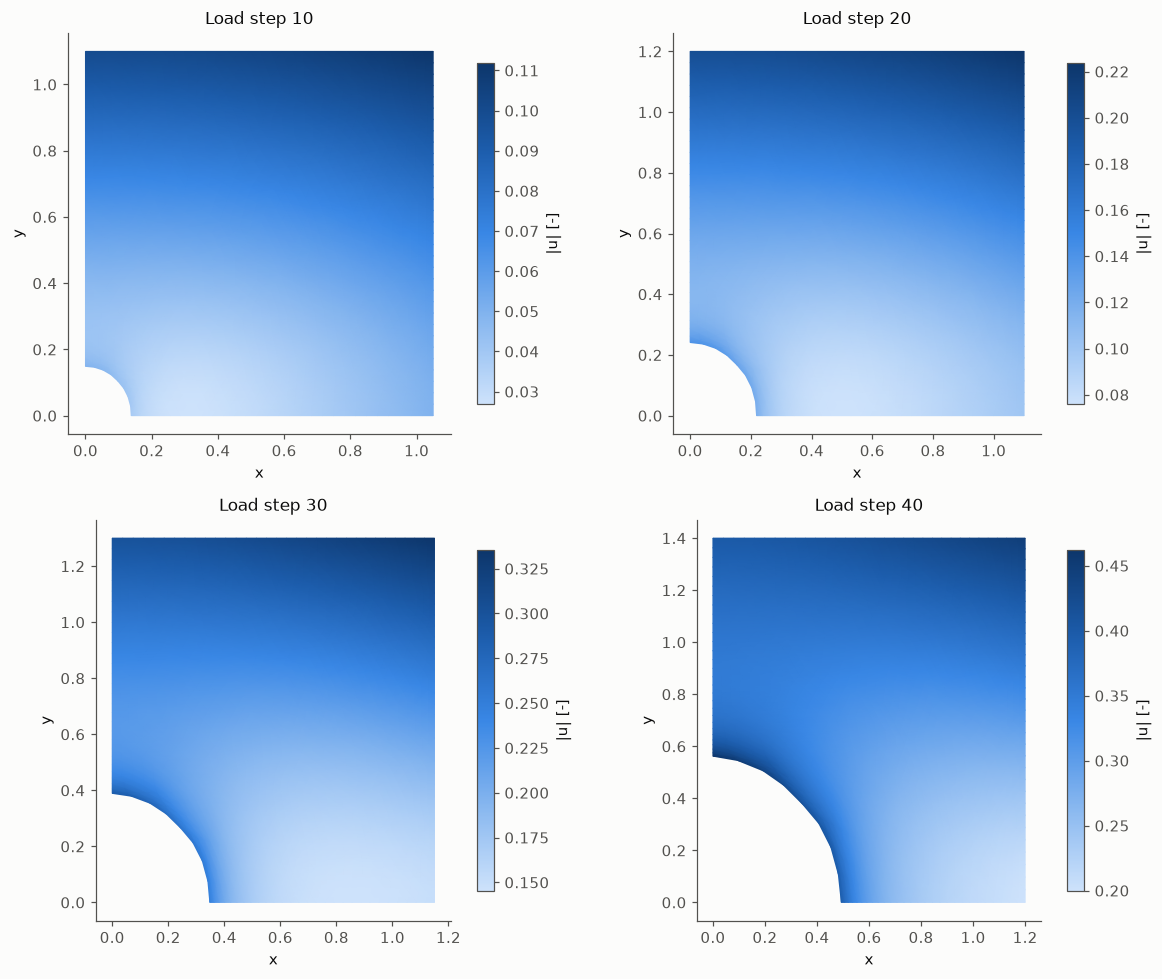

In [8]:
figure, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, step in zip(axes.flat, field_steps):
    magnitude = np.linalg.norm(step.displacement, axis=1)
    plotting.plot_nodal_field(step, magnitude, ax, f"Load step {step.load_step}", "|u| [-]")
figure.tight_layout()
plotting.save_figure(figure, "source3_overview", FIGURES)
plt.show()

The displacement grows with the load step, and the deformation is large.
At load step 40, the hole edge on the x-axis moves from $x = 0.1$ to about $x = 0.5$.
The hole concentrates the deformation near its edge.

## 4. The equation as a graph

In [9]:
yeoh3 = models.yeoh_variant(3)
print("DEAP prefix expression:", yeoh3.tree)
print("Number of tree nodes:  ", len(yeoh3.tree))
display(Math("W = " + sp.latex(yeoh3.sympy_expression())))

DEAP prefix expression: add(add(mul(C10, sub(I1b, 3)), mul(C20, pow(sub(I1b, 3), 2))), mul(C30, pow(sub(I1b, 3), 3)))
Number of tree nodes:   21


<IPython.core.display.Math object>

**DAG of the balance law.** The graph below follows the chain
$u \to F \to (\bar I_1, J) \to W(\theta) \to P = \partial W / \partial F \to \operatorname{Div} P$
for the Yeoh $N=3$ + volumetric variant.
Blue nodes are observed variables, orange nodes are parameters, green nodes are operations and gray nodes are constants.
A magenta ring marks a shared node: a node with more than one consumer.
Shared constants such as 2 and 3 get no ring, because they carry no structural information.

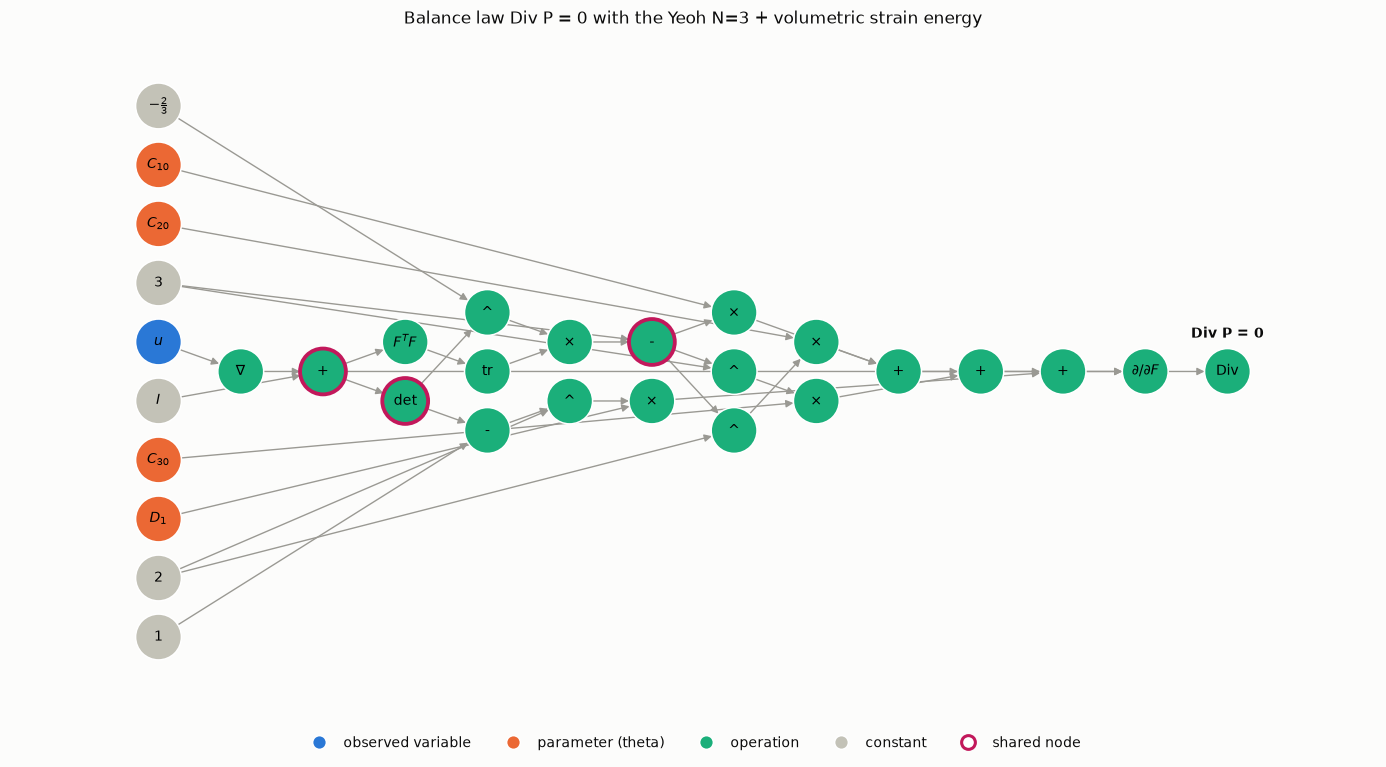

Shared nodes: ['+', 'det', '-']


In [10]:
field_yeoh3 = models.yeoh_variant(3, compressible=True)
equilibrium_dag, named_nodes = graph.build_equilibrium_dag(field_yeoh3)
figure, ax = plt.subplots(figsize=(16, 8))
plotting.plot_dag(
    equilibrium_dag,
    ax,
    "Balance law Div P = 0 with the Yeoh N=3 + volumetric strain energy",
    root_labels={named_nodes["Div P"]: "Div P = 0"},
)
plotting.save_figure(figure, "equilibrium_dag", FIGURES)
plt.show()
print("Shared nodes:", [equilibrium_dag.nodes[i].label for i in equilibrium_dag.shared_nodes()])

$F$ feeds three operations: $C = F^{\mathsf T}F$, $\det F$ and $\partial W/\partial F$.
The subexpression $(\bar I_1 - 3)$ feeds all three Yeoh terms.
$J$ feeds both the isochoric invariant and the volumetric term.

The adjacency matrix uses the convention of the course example: $Z_{ij} = 1$ if node $j$ is an input of node $i$.

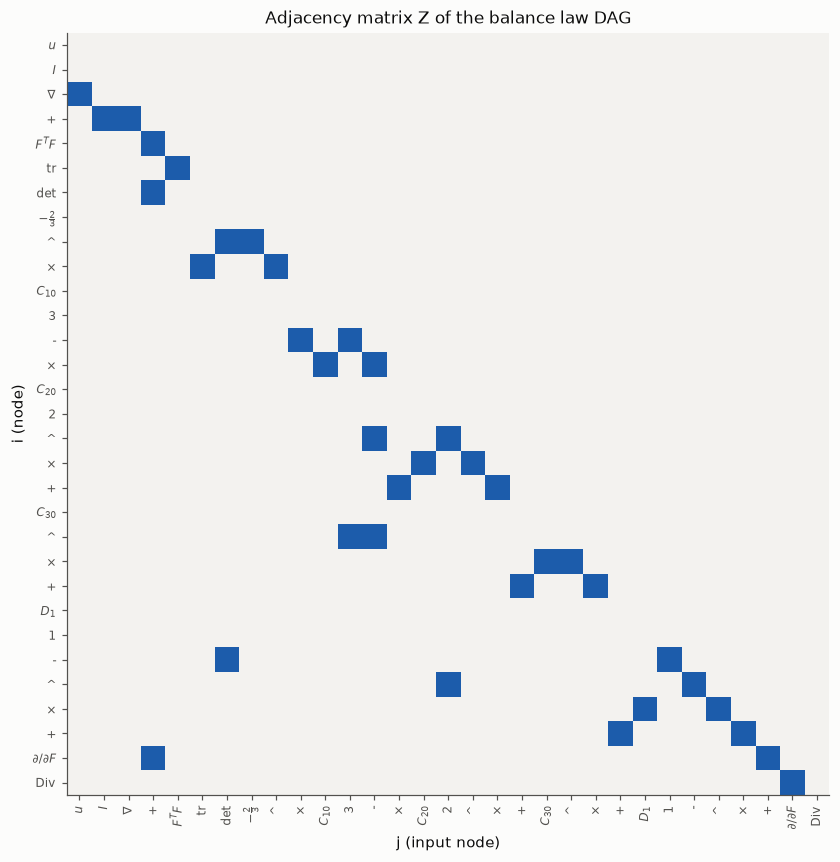

In [11]:
figure, ax = plt.subplots(figsize=(9, 9))
plotting.plot_adjacency(equilibrium_dag, ax, "Adjacency matrix Z of the balance law DAG")
plotting.save_figure(figure, "equilibrium_adjacency", FIGURES)
plt.show()

**Superposition of the variants.** One DAG can hold several variants.
Equal subexpressions of different variants map to one node.
The graph shows that each Yeoh tree contains the tree of the lower order:
the root of $N=1$ feeds the root of $N=2$, and the root of $N=2$ feeds the root of $N=3$.
The Ogden tree shares no operation with the Yeoh trees, so the next figure compares it by the tree edit distance.

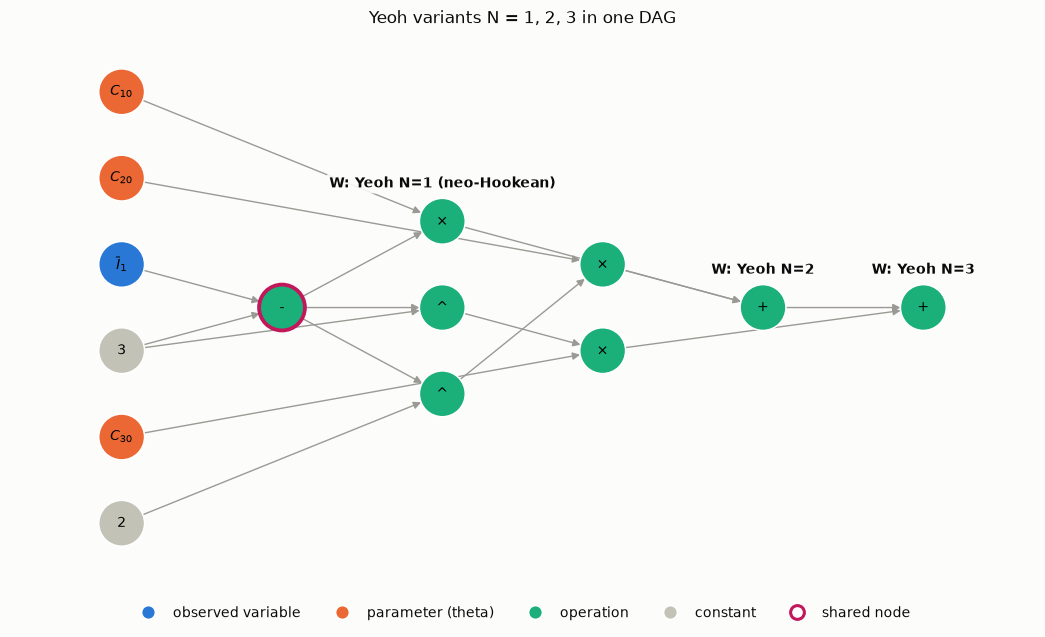

In [12]:
yeoh_variants = [models.yeoh_variant(order) for order in (1, 2, 3)]
variants_dag, roots = graph.build_variants_dag(yeoh_variants)
titles = {variant.name: variant.title for variant in yeoh_variants}
figure, ax = plt.subplots(figsize=(12, 6.5))
plotting.plot_dag(
    variants_dag,
    ax,
    "Yeoh variants N = 1, 2, 3 in one DAG",
    root_labels={index: f"W: {titles[name]}" for name, index in roots.items()},
)
plotting.save_figure(figure, "variants_dag", FIGURES)
plt.show()

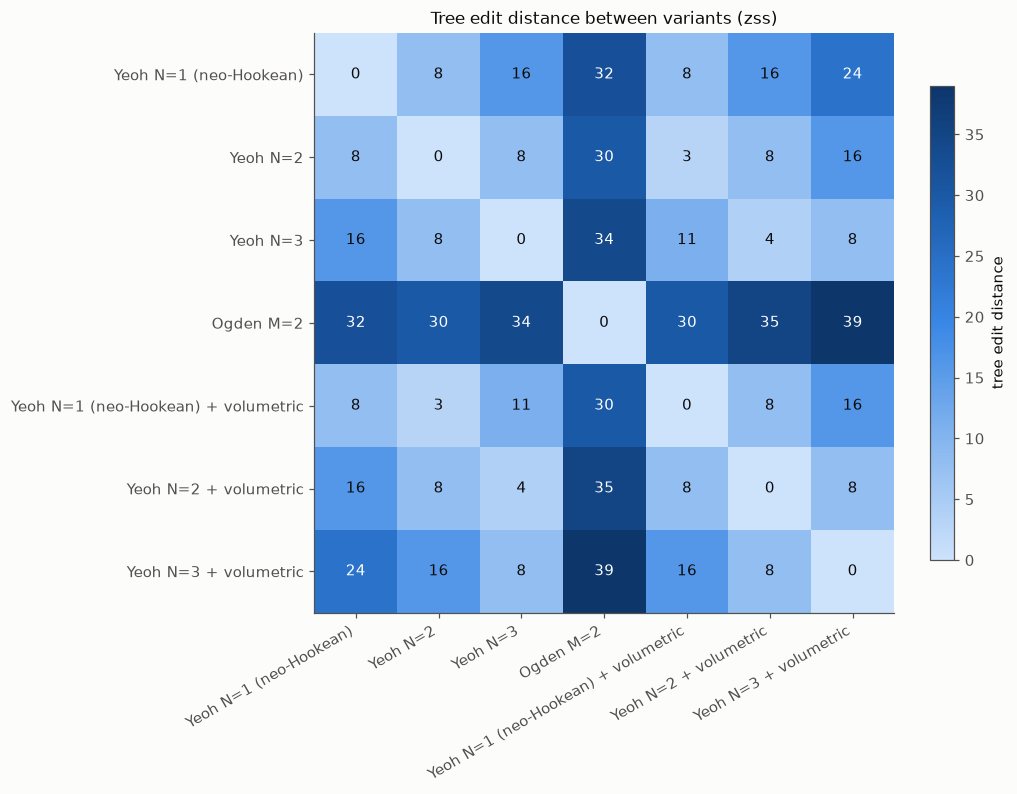

In [13]:
distances = evaluation.tree_distance_table(HOMOGENEOUS_VARIANTS + FIELD_VARIANTS)
figure, ax = plt.subplots(figsize=(8.5, 7))
plotting.plot_distance_matrix(distances, ax, "Tree edit distance between variants (zss)")
plotting.save_figure(figure, "tree_distances", FIGURES)
plt.show()

Each additional Yeoh order costs 8 node insertions. The volumetric term also costs 8.
The Ogden tree shares only the outer structure with the Yeoh trees, so its distance is the largest.

The tree edit distance measures structure, not meaning.
Yeoh $N=2$ and Yeoh $N=1$ + volumetric are only 3 relabels apart.
Both add one term of the same shape: $C_{20} \leftrightarrow D_1$, $\bar I_1 \leftrightarrow J$ and $3 \leftrightarrow 1$.
So the distance is a measure of model complexity, independent of the data.

## 5. Parameter vectors and expected values

Each variant has its own parameter vector $\theta$, in the order of its parameter names.
The tables list the expected value of each parameter, its reference, the bounds, the CMA-ES scale and the start point.
A missing expected value means that no reference gives that parameter for that variant and source.

In [14]:
for source_key, variants in (
    (SRMD, HOMOGENEOUS_VARIANTS),
    (TRELOAR, HOMOGENEOUS_VARIANTS),
    (EUCLID, FIELD_VARIANTS),
):
    print(f"Source: {source_key}")
    display(parameters.specs_overview(variants, source_key))

Source: srmd_ecoflex_00_30


expected  \
name   variant                            
C10    Yeoh N=1 (neo-Hookean)   0.01622   
       Yeoh N=2                     NaN   
C20    Yeoh N=2                     NaN   
C10    Yeoh N=3                     0.1   
C20    Yeoh N=3                   0.012   
C30    Yeoh N=3                4.96e-05   
mu1    Ogden M=2                    NaN   
alpha1 Ogden M=2                    NaN   
mu2    Ogden M=2                    NaN   
alpha2 Ogden M=2                    NaN   

                                                                       reference  \
name   variant                                                                     
C10    Yeoh N=1 (neo-Hookean)            Marechal et al. 2021, Table III: mu / 2   
       Yeoh N=2                                                                    
C20    Yeoh N=2                                                                    
C10    Yeoh N=3                Marechal et al. 2021, Table III (true stress fit)   
C20    Yeoh N=3                Marechal et al. 2021, Table III (true stress fit)   
C30    Yeoh N=3                Marechal et al. 2021, Table III (true stress fit)   
mu1    Ogden M=2                                                                   
alpha1 Ogden M=2                                                                   
mu2    Ogden M=2                                                                   
alpha2 Ogden M=2                                                                   

                               lower  upper  scale  initial unit  
name   variant                                                    
C10    Yeoh N=1 (neo-Hookean)      0      3   0.03  0.01622  MPa  
       Yeoh N=2                    0      3   0.03     0.03  MPa  
C20    Yeoh N=2                 -0.3    0.3  0.003        0  MPa  
C10    Yeoh N=3                    0      3   0.03      0.1  MPa  
C20    Yeoh N=3                 -0.3    0.3  0.003    0.012  MPa  
C30    Yeoh N=3                -0.03   0.03 0.0003 4.96e-05  MPa  
mu1    Ogden M=2                   0      3   0.03     0.03  MPa  
alpha1 Ogden M=2                 0.1     20      1        2    -  
mu2    Ogden M=2                   0      3   0.03   0.0003  MPa  
alpha2 Ogden M=2                 0.1     20      1        5    -

Source: treloar_1944


expected  \
name   variant                            
C10    Yeoh N=1 (neo-Hookean)    0.2112   
       Yeoh N=2                  0.2112   
C20    Yeoh N=2                     NaN   
C10    Yeoh N=3                  0.2112   
C20    Yeoh N=3                     NaN   
C30    Yeoh N=3                     NaN   
mu1    Ogden M=2                   0.63   
alpha1 Ogden M=2                    1.3   
mu2    Ogden M=2                 0.0012   
alpha2 Ogden M=2                      5   

                                                                       reference  \
name   variant                                                                     
C10    Yeoh N=1 (neo-Hookean)  mu0 / 2, mu0 = 0.4225 MPa from the Ogden 1972 fit   
       Yeoh N=2                mu0 / 2, mu0 = 0.4225 MPa from the Ogden 1972 fit   
C20    Yeoh N=2                                                                    
C10    Yeoh N=3                mu0 / 2, mu0 = 0.4225 MPa from the Ogden 1972 fit   
C20    Yeoh N=3                                                                    
C30    Yeoh N=3                                                                    
mu1    Ogden M=2                 Ogden 1972, two leading terms of the 3-term fit   
alpha1 Ogden M=2                 Ogden 1972, two leading terms of the 3-term fit   
mu2    Ogden M=2                 Ogden 1972, two leading terms of the 3-term fit   
alpha2 Ogden M=2                 Ogden 1972, two leading terms of the 3-term fit   

                               lower  upper  scale  initial unit  
name   variant                                                    
C10    Yeoh N=1 (neo-Hookean)      0     30    0.3   0.2112  MPa  
       Yeoh N=2                    0     30    0.3   0.2112  MPa  
C20    Yeoh N=2                   -3      3   0.03        0  MPa  
C10    Yeoh N=3                    0     30    0.3   0.2112  MPa  
C20    Yeoh N=3                   -3      3   0.03        0  MPa  
C30    Yeoh N=3                 -0.3    0.3  0.003        0  MPa  
mu1    Ogden M=2                   0     30    0.3     0.63  MPa  
alpha1 Ogden M=2                 0.1     20      1      1.3    -  
mu2    Ogden M=2                   0     30    0.3   0.0012  MPa  
alpha2 Ogden M=2                 0.1     20      1        5    -

Source: euclid_plate_hole


,,expected,reference,lower,upper,scale,initial,unit
name,variant,,,,,,,
C10,Yeoh N=1 (neo-Hookean) + volumetric,0.5,Data generator of Flaschel et al. 2021 (exact),0,100,1,0.5,-
D1,Yeoh N=1 (neo-Hookean) + volumetric,1.5,Data generator of Flaschel et al. 2021 (exact),0,100,1,1.5,-
C10,Yeoh N=2 + volumetric,0.5,Data generator of Flaschel et al. 2021 (exact),0,100,1,0.5,-
C20,Yeoh N=2 + volumetric,0,Data generator of Flaschel et al. 2021 (exact),-10,10,0.1,0,-
D1,Yeoh N=2 + volumetric,1.5,Data generator of Flaschel et al. 2021 (exact),0,100,1,1.5,-
C10,Yeoh N=3 + volumetric,0.5,Data generator of Flaschel et al. 2021 (exact),0,100,1,0.5,-
C20,Yeoh N=3 + volumetric,0,Data generator of Flaschel et al. 2021 (exact),-10,10,0.1,0,-
C30,Yeoh N=3 + volumetric,0,Data generator of Flaschel et al. 2021 (exact),-1,1,0.01,0,-
D1,Yeoh N=3 + volumetric,1.5,Data generator of Flaschel et al. 2021 (exact),0,100,1,1.5,-


**Notes on the expected values.**
- *Source 1.* Marechal et al. (2021, Table III) fit true stress against true strain over the full curve.
  Their neo-Hookean $\mu = 0.03245$ MPa gives $C_{10} = \mu / 2$.
  Their Yeoh $C_1 = 0.100$ MPa disagrees with their own neo-Hookean value by a factor of 6. We keep it as printed and check it below.
- *Source 2.* Ogden (1972) fit three terms. The two leading terms serve as the expected Ogden $M=2$ values.
  The initial shear modulus of that fit, $\mu_0 = \tfrac12 \sum_p \mu_p \alpha_p = 0.4225$ MPa, gives the expected $C_{10} = \mu_0/2$.
- *Source 3.* The data generator used $C_{10} = 0.5$ and $D_1 = 1.5$. These values are exact.

## 6. Optimizers and solver

Every fit minimizes the cost $\tfrac12 \lVert r(\theta) \rVert^2$ of a residual vector $r$.

| Optimizer | Type | Use | Tradeoff |
|---|---|---|---|
| Bounded linear least squares | direct | Yeoh variants only | Exact global minimum, but only for a residual that is linear in $\theta$ |
| Levenberg–Marquardt (LM) | gradient-based, local | all variants | Fast; torch autograd gives the Jacobian; ignores bounds; can stop in a local minimum |
| CMA-ES | derivative-free, global | all variants | Robust to local minima; uses 100× more evaluations; needs a fixed seed |

The Yeoh residual is linear in $\theta$, because $W$ is a linear sum of its coefficients.
So linear least squares gives the reference optimum, and LM and CMA-ES must reproduce it.
The Ogden residual is nonlinear in $\alpha_p$. There, LM and CMA-ES are the real comparison.

**Residuals.**
- Homogeneous tests use the relative stress residual $r_k = (P_{\text{model}} - P_k)/P_k$.
  It gives the small-stress points the same weight as the large-stress points.
- The field test uses the weak-form residual at the measured displacements:
  the internal forces at the free degrees of freedom, and the reaction force mismatch times $\sqrt{\beta}$ with $\beta = 100$, as in Flaschel et al. (2021).
  This residual needs no forward solve, and it is linear in $\theta$ for the Yeoh family.

**Solvers.**
- Homogeneous tests: torch autograd evaluates $P = \mathrm d\hat W/\mathrm d\lambda$ directly.
- Field test: L-BFGS-B minimizes $\Pi(u)$ over the free nodes, with the measured boundary displacements.
  This forward solve predicts the full displacement field for a given $\theta$.

## 7. Source 1: Ecoflex 00-30, uniaxial test

All four variants are fitted to the same uniaxial curve with every optimizer.

In [15]:
srmd_results = experiment.fit_homogeneous(HOMOGENEOUS_VARIANTS, [srmd_test], SRMD)
display(experiment.optimizer_table(HOMOGENEOUS_VARIANTS, srmd_results))

cost  evaluations      C10  \
variant                optimizer                                           
Yeoh N=1 (neo-Hookean) Linear least squares  76.48            3  0.01257   
                       Levenberg-Marquardt   76.48            2  0.01257   
                       CMA-ES                76.48          264  0.01257   
Yeoh N=2               Linear least squares  1.543            4 0.008285   
                       Levenberg-Marquardt   1.543            2 0.008285   
                       CMA-ES                1.543          630 0.008285   
Yeoh N=3               Linear least squares 0.6741            5   0.0078   
                       Levenberg-Marquardt  0.6741            2   0.0078   
                       CMA-ES               0.6741         1162   0.0078   
Ogden M=2              Levenberg-Marquardt  0.4631           21      NaN   
                       CMA-ES               0.4631         2320      NaN   

                                                  C20        C30     mu1  \
variant                optimizer                                           
Yeoh N=1 (neo-Hookean) Linear least squares       NaN        NaN     NaN   
                       Levenberg-Marquardt        NaN        NaN     NaN   
                       CMA-ES                     NaN        NaN     NaN   
Yeoh N=2               Linear least squares 6.223e-05        NaN     NaN   
                       Levenberg-Marquardt  6.223e-05        NaN     NaN   
                       CMA-ES               6.223e-05        NaN     NaN   
Yeoh N=3               Linear least squares 7.928e-05 -5.807e-08     NaN   
                       Levenberg-Marquardt  7.928e-05 -5.807e-08     NaN   
                       CMA-ES               7.928e-05 -5.807e-08     NaN   
Ogden M=2              Levenberg-Marquardt        NaN        NaN 0.01227   
                       CMA-ES                     NaN        NaN 0.01227   

                                             alpha1       mu2  alpha2  
variant                optimizer                                       
Yeoh N=1 (neo-Hookean) Linear least squares     NaN       NaN     NaN  
                       Levenberg-Marquardt      NaN       NaN     NaN  
                       CMA-ES                   NaN       NaN     NaN  
Yeoh N=2               Linear least squares     NaN       NaN     NaN  
                       Levenberg-Marquardt      NaN       NaN     NaN  
                       CMA-ES                   NaN       NaN     NaN  
Yeoh N=3               Linear least squares     NaN       NaN     NaN  
                       Levenberg-Marquardt      NaN       NaN     NaN  
                       CMA-ES                   NaN       NaN     NaN  
Ogden M=2              Levenberg-Marquardt    2.189 0.0003699     3.8  
                       CMA-ES                 2.189 0.0003699     3.8

All three optimizers reach the same cost for every Yeoh variant.
Linear least squares gives the exact optimum, and LM and CMA-ES reproduce it.
LM needs 2 evaluations. CMA-ES needs 264 to 1162 evaluations.

For Ogden $M=2$, LM and CMA-ES also agree (cost 0.4631). LM needs 21 evaluations, CMA-ES needs 2320.
The loss has no competing minimum near the start point, so the global search brings no gain here.
Its price is about 100 times more evaluations.

In [16]:
display(experiment.stress_metrics_table(HOMOGENEOUS_VARIANTS, srmd_results, [srmd_test], (data.UNIAXIAL,)))
display(experiment.expected_table(HOMOGENEOUS_VARIANTS, srmd_results, SRMD))
display(experiment.stability_table(HOMOGENEOUS_VARIANTS, srmd_results, evaluation.max_first_invariant(srmd_test)))

,,source,relative_rmse,r_squared,n_points,role
variant,mode,,,,,
Yeoh N=1 (neo-Hookean),uniaxial,srmd_ecoflex_00_30,0.4658,0.1192,705,train
Yeoh N=2,uniaxial,srmd_ecoflex_00_30,0.06616,0.9913,705,train
Yeoh N=3,uniaxial,srmd_ecoflex_00_30,0.04373,0.9997,705,train
Ogden M=2,uniaxial,srmd_ecoflex_00_30,0.03624,0.9995,705,train


expected     fitted  fitted - expected  \
parameter variant                                                          
C10       Yeoh N=1 (neo-Hookean)   0.01622    0.01257          -0.003651   
          Yeoh N=2                     NaN   0.008285                NaN   
C20       Yeoh N=2                     NaN  6.223e-05                NaN   
C10       Yeoh N=3                     0.1     0.0078            -0.0922   
C20       Yeoh N=3                   0.012  7.928e-05           -0.01192   
C30       Yeoh N=3                4.96e-05 -5.807e-08         -4.966e-05   
mu1       Ogden M=2                    NaN    0.01227                NaN   
alpha1    Ogden M=2                    NaN      2.189                NaN   
mu2       Ogden M=2                    NaN  0.0003699                NaN   
alpha2    Ogden M=2                    NaN        3.8                NaN   

                                  fitted / expected unit  \
parameter variant                                          
C10       Yeoh N=1 (neo-Hookean)              0.775  MPa   
          Yeoh N=2                              NaN  MPa   
C20       Yeoh N=2                              NaN  MPa   
C10       Yeoh N=3                            0.078  MPa   
C20       Yeoh N=3                         0.006606  MPa   
C30       Yeoh N=3                        -0.001171  MPa   
mu1       Ogden M=2                             NaN  MPa   
alpha1    Ogden M=2                             NaN    -   
mu2       Ogden M=2                             NaN  MPa   
alpha2    Ogden M=2                             NaN    -   

                                                                          reference  
parameter variant                                                                    
C10       Yeoh N=1 (neo-Hookean)            Marechal et al. 2021, Table III: mu / 2  
          Yeoh N=2                                                                   
C20       Yeoh N=2                                                                   
C10       Yeoh N=3                Marechal et al. 2021, Table III (true stress fit)  
C20       Yeoh N=3                Marechal et al. 2021, Table III (true stress fit)  
C30       Yeoh N=3                Marechal et al. 2021, Table III (true stress fit)  
mu1       Ogden M=2                                                                  
alpha1    Ogden M=2                                                                  
mu2       Ogden M=2                                                                  
alpha2    Ogden M=2

,min dW/dI1,stable
variant,,
Yeoh N=1 (neo-Hookean),0.01257,True
Yeoh N=2,0.008285,True
Yeoh N=3,0.0078,True


**Errors.** The neo-Hookean variant fails: relative RMSE 0.47 and $R^2 = 0.12$.
One parameter cannot follow both the soft start and the stiffening.
Yeoh $N=2$ reduces the relative RMSE to 0.066, Yeoh $N=3$ to 0.044 and Ogden $M=2$ to 0.036.

**Expected values.** The neo-Hookean fit gives $C_{10} = 0.0126$ MPa, 0.78 times the published value.
The difference comes from the stress measure and the weights of the fit (Section 12).
The published Yeoh $C_1 = 0.100$ MPa is 13 times the fitted $C_{10} = 0.0078$ MPa.
That value also conflicts with the published neo-Hookean $\mu$, so the table value is probably a typo.

**Stability.** Every Yeoh fit keeps $\partial W / \partial \bar I_1 > 0$ over the measured range, so it is stable there.
Yeoh $N=3$ has $C_{30} < 0$. Its $\partial W / \partial \bar I_1$ turns negative at $\bar I_1 - 3 \approx 960$, far beyond the data.
So this fit must not extrapolate to larger stretches.

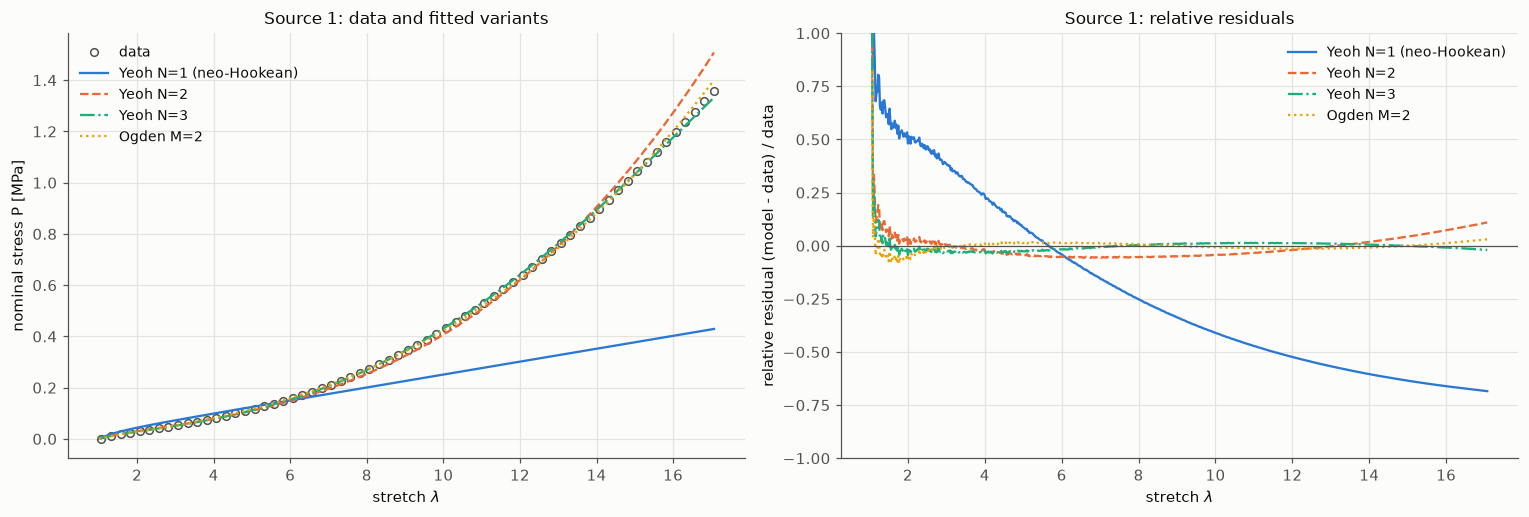

In [17]:
stretch_grid = np.linspace(1.0, srmd_test.stretch.max(), 300)
figure, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plotting.plot_test_data(srmd_test, axes[0], "data")
plotting.plot_model_curves(
    stretch_grid,
    experiment.stress_curves(HOMOGENEOUS_VARIANTS, srmd_results, data.UNIAXIAL, stretch_grid),
    axes[0],
)
plotting.label_stress_axes(axes[0], "MPa", "Source 1: data and fitted variants")
plotting.plot_relative_residuals(
    srmd_test.stretch,
    experiment.relative_residuals(HOMOGENEOUS_VARIANTS, srmd_results, srmd_test),
    axes[1],
    "Source 1: relative residuals",
)
axes[1].set_ylim(-1.0, 1.0)
figure.tight_layout()
plotting.save_figure(figure, "source1_fits", FIGURES)
plt.show()

The neo-Hookean curve lies above the data below $\lambda \approx 6$ and below the data above it.
Yeoh $N=2$ overshoots above $\lambda \approx 14$.
Yeoh $N=3$ and Ogden $M=2$ follow the data over the full range.
All variants show large relative residuals below $\lambda \approx 1.3$.
There the stress is 0.01 MPa or less, and the crosshead strain has its largest uncertainty.

## 8. Source 2: Treloar, fit on uniaxial, test on equibiaxial and pure shear

The fit uses only the uniaxial curve. The equibiaxial and pure shear curves test the prediction.
This split checks whether a variant describes the material or only fits one curve.

In [18]:
treloar_uniaxial = treloar_tests[0]
treloar_results = experiment.fit_homogeneous(HOMOGENEOUS_VARIANTS, [treloar_uniaxial], TRELOAR)
display(experiment.optimizer_table(HOMOGENEOUS_VARIANTS, treloar_results))
display(experiment.expected_table(HOMOGENEOUS_VARIANTS, treloar_results, TRELOAR))

cost  evaluations    C10  \
variant                optimizer                                           
Yeoh N=1 (neo-Hookean) Linear least squares   0.2558            3 0.1749   
                       Levenberg-Marquardt    0.2558            2 0.1749   
                       CMA-ES                 0.2558          248 0.1749   
Yeoh N=2               Linear least squares    0.119            4 0.1474   
                       Levenberg-Marquardt     0.119            2 0.1474   
                       CMA-ES                  0.119          594 0.1474   
Yeoh N=3               Linear least squares  0.02151            5 0.1717   
                       Levenberg-Marquardt   0.02151            2 0.1717   
                       CMA-ES                0.02151          756 0.1717   
Ogden M=2              Levenberg-Marquardt  0.004575            7    NaN   
                       CMA-ES               0.004575         2056    NaN   

                                                  C20       C30    mu1  \
variant                optimizer                                         
Yeoh N=1 (neo-Hookean) Linear least squares       NaN       NaN    NaN   
                       Levenberg-Marquardt        NaN       NaN    NaN   
                       CMA-ES                     NaN       NaN    NaN   
Yeoh N=2               Linear least squares  0.000958       NaN    NaN   
                       Levenberg-Marquardt   0.000958       NaN    NaN   
                       CMA-ES                0.000958       NaN    NaN   
Yeoh N=3               Linear least squares -0.001458 3.863e-05    NaN   
                       Levenberg-Marquardt  -0.001458 3.863e-05    NaN   
                       CMA-ES               -0.001458 3.863e-05    NaN   
Ogden M=2              Levenberg-Marquardt        NaN       NaN 0.5779   
                       CMA-ES                     NaN       NaN 0.5779   

                                             alpha1      mu2  alpha2  
variant                optimizer                                      
Yeoh N=1 (neo-Hookean) Linear least squares     NaN      NaN     NaN  
                       Levenberg-Marquardt      NaN      NaN     NaN  
                       CMA-ES                   NaN      NaN     NaN  
Yeoh N=2               Linear least squares     NaN      NaN     NaN  
                       Levenberg-Marquardt      NaN      NaN     NaN  
                       CMA-ES                   NaN      NaN     NaN  
Yeoh N=3               Linear least squares     NaN      NaN     NaN  
                       Levenberg-Marquardt      NaN      NaN     NaN  
                       CMA-ES                   NaN      NaN     NaN  
Ogden M=2              Levenberg-Marquardt     1.35 0.001083    5.03  
                       CMA-ES                  1.35 0.001082   5.031

expected    fitted  fitted - expected  \
parameter variant                                                         
C10       Yeoh N=1 (neo-Hookean)    0.2112    0.1749           -0.03634   
          Yeoh N=2                  0.2112    0.1474           -0.06384   
C20       Yeoh N=2                     NaN  0.000958                NaN   
C10       Yeoh N=3                  0.2112    0.1717           -0.03954   
C20       Yeoh N=3                     NaN -0.001458                NaN   
C30       Yeoh N=3                     NaN 3.863e-05                NaN   
mu1       Ogden M=2                   0.63    0.5779           -0.05207   
alpha1    Ogden M=2                    1.3      1.35            0.05023   
mu2       Ogden M=2                 0.0012  0.001082         -0.0001175   
alpha2    Ogden M=2                      5     5.031             0.0305   

                                  fitted / expected unit  \
parameter variant                                          
C10       Yeoh N=1 (neo-Hookean)              0.828  MPa   
          Yeoh N=2                           0.6978  MPa   
C20       Yeoh N=2                              NaN  MPa   
C10       Yeoh N=3                           0.8128  MPa   
C20       Yeoh N=3                              NaN  MPa   
C30       Yeoh N=3                              NaN  MPa   
mu1       Ogden M=2                          0.9174  MPa   
alpha1    Ogden M=2                           1.039    -   
mu2       Ogden M=2                          0.9021  MPa   
alpha2    Ogden M=2                           1.006    -   

                                                                          reference  
parameter variant                                                                    
C10       Yeoh N=1 (neo-Hookean)  mu0 / 2, mu0 = 0.4225 MPa from the Ogden 1972 fit  
          Yeoh N=2                mu0 / 2, mu0 = 0.4225 MPa from the Ogden 1972 fit  
C20       Yeoh N=2                                                                   
C10       Yeoh N=3                mu0 / 2, mu0 = 0.4225 MPa from the Ogden 1972 fit  
C20       Yeoh N=3                                                                   
C30       Yeoh N=3                                                                   
mu1       Ogden M=2                 Ogden 1972, two leading terms of the 3-term fit  
alpha1    Ogden M=2                 Ogden 1972, two leading terms of the 3-term fit  
mu2       Ogden M=2                 Ogden 1972, two leading terms of the 3-term fit  
alpha2    Ogden M=2                 Ogden 1972, two leading terms of the 3-term fit

Again all optimizers agree.
The Ogden $M=2$ fit lands close to the published values of Ogden (1972):
$\mu_1 = 0.578$ MPa (expected 0.63), $\alpha_1 = 1.35$ (1.3), $\mu_2 = 0.00108$ MPa (0.0012) and $\alpha_2 = 5.03$ (5.0).
The Yeoh $C_{10}$ lies 17 % to 30 % below the expected $\mu_0 / 2$.
A uniaxial fit spreads the stiffness over several coefficients, so $C_{10}$ alone is not the small-strain modulus.

In [19]:
treloar_metrics = experiment.stress_metrics_table(
    HOMOGENEOUS_VARIANTS, treloar_results, treloar_tests, (data.UNIAXIAL,)
)
display(treloar_metrics[["role", "relative_rmse", "r_squared", "n_points"]])

role  relative_rmse  r_squared  n_points
variant                mode                                                  
Yeoh N=1 (neo-Hookean) uniaxial     train         0.1984     0.7151        13
                       equibiaxial   test         0.1996     0.7506        13
                       pure_shear    test        0.06288     0.9916        13
Yeoh N=2               uniaxial     train         0.1353     0.9369        13
                       equibiaxial   test           0.22     0.8977        13
                       pure_shear    test         0.1292     0.9855        13
Yeoh N=3               uniaxial     train        0.05752     0.9982        13
                       equibiaxial   test         0.1991      0.858        13
                       pure_shear    test         0.0703     0.9828        13
Ogden M=2              uniaxial     train        0.02653     0.9977        13
                       equibiaxial   test         0.2257     0.6244        13
                       pure_shear    test        0.08084     0.9866        13

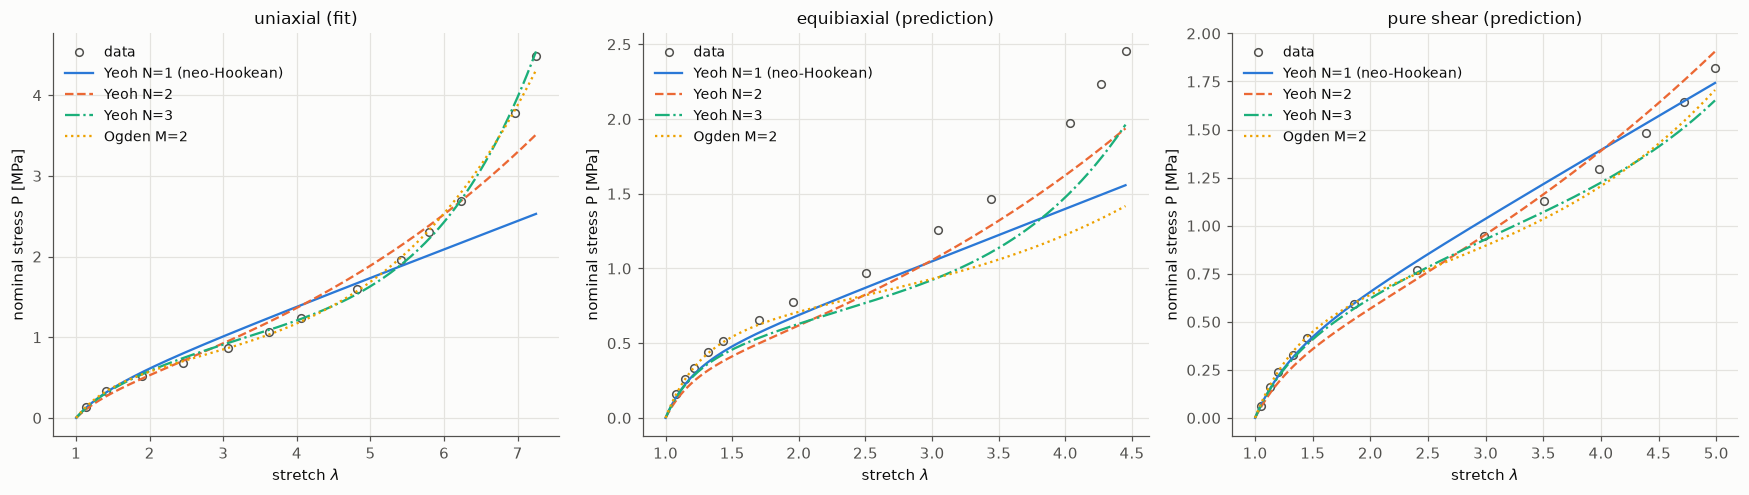

In [20]:
figure, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, test in zip(axes, treloar_tests):
    grid = np.linspace(1.0, test.stretch.max(), 200)
    plotting.plot_test_data(test, ax, "data")
    plotting.plot_model_curves(
        grid, experiment.stress_curves(HOMOGENEOUS_VARIANTS, treloar_results, test.mode, grid), ax
    )
    role = "fit" if test.mode == data.UNIAXIAL else "prediction"
    plotting.label_stress_axes(ax, "MPa", f"{test.mode.replace('_', ' ')} ({role})")
figure.tight_layout()
plotting.save_figure(figure, "source2_fits", FIGURES)
plt.show()

**This is the main result of Section 8.**
On the fitted uniaxial curve, Ogden $M=2$ is best (relative RMSE 0.027), followed by Yeoh $N=3$ (0.058).
On the equibiaxial curve, every variant predicts too little stress over most of the range.
Ogden $M=2$ is the worst there (relative RMSE 0.23, $R^2 = 0.62$).
On pure shear, the neo-Hookean variant is the best (0.063).

So a better fit to one test mode does not give a better prediction of the other modes.
Uniaxial data alone does not identify $W$: several functions fit it equally well and differ under biaxial stretch.
The remedy is a fit to several test modes together.

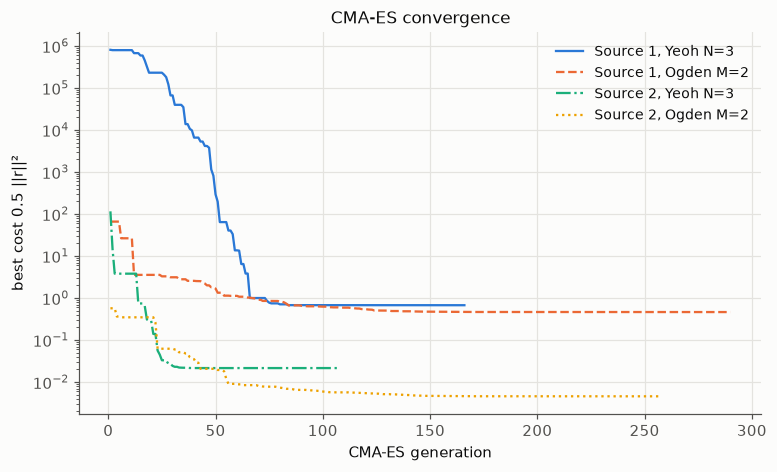

In [21]:
histories = {
    "Source 1, Yeoh N=3": srmd_results["yeoh3"][experiment.CMA_ES].history,
    "Source 1, Ogden M=2": srmd_results["ogden2"][experiment.CMA_ES].history,
    "Source 2, Yeoh N=3": treloar_results["yeoh3"][experiment.CMA_ES].history,
    "Source 2, Ogden M=2": treloar_results["ogden2"][experiment.CMA_ES].history,
}
figure, ax = plt.subplots(figsize=(8, 4.5))
plotting.plot_cost_history(histories, ax)
plotting.save_figure(figure, "cma_es_convergence", FIGURES)
plt.show()

The Yeoh fits settle within 35 to 85 generations. The Ogden fits need about 150 generations.
After that, each curve stays flat until the stop tolerance ends the run.
A looser tolerance would save about half of the evaluations.

## 9. Source 3: field data through the weak form

**9.1 Verification.** With the generator parameters, the model must reproduce the published stresses,
internal forces and reaction forces of every load step. This check tests the kinematics,
the strain energy tree and the autograd stress together.

In [22]:
true_theta = parameters.expected_vector(parameters.parameter_specs(FIELD_VARIANTS[0], EUCLID))
display(experiment.verification_table(FIELD_VARIANTS[0], true_theta, field_steps))

,max |P - P_source|,max |f - f_source|,max |R - R_source|,max |P_source|
load step,,,,
10,3.531e-14,7.966e-15,1.036e-13,1.059
20,6.883e-14,1.618e-14,2.149e-13,1.917
30,1.532e-13,2.433e-14,3.277e-13,4.626
40,7.23e-13,6.425e-14,3.662e-13,12.6


Every difference is at round-off level (below $10^{-12}$), while the stress reaches 12.6.
So the kinematics, the strain energy tree and the autograd stress reproduce the solver of Flaschel et al. (2021).

**9.2 Identification.** The fit uses load steps 10 and 20. Load steps 30 and 40 test the prediction later in the load history.

In [23]:
TRAIN_STEPS = (10, 20)
train_steps = [step for step in field_steps if step.load_step in TRAIN_STEPS]
field_results = experiment.fit_field(FIELD_VARIANTS, train_steps, EUCLID, balance=100.0)
display(experiment.optimizer_table(FIELD_VARIANTS, field_results))
display(experiment.expected_table(FIELD_VARIANTS, field_results, EUCLID))

cost  \
variant                             optimizer                        
Yeoh N=1 (neo-Hookean) + volumetric Linear least squares 1.641e-23   
                                    Levenberg-Marquardt   1.64e-23   
                                    CMA-ES               1.336e-16   
Yeoh N=2 + volumetric               Linear least squares  1.44e-23   
                                    Levenberg-Marquardt   1.44e-23   
                                    CMA-ES               1.174e-15   
Yeoh N=3 + volumetric               Linear least squares 9.763e-24   
                                    Levenberg-Marquardt  9.765e-24   
                                    CMA-ES               3.161e-16   

                                                          evaluations  C10  \
variant                             optimizer                                
Yeoh N=1 (neo-Hookean) + volumetric Linear least squares            4  0.5   
                                    Levenberg-Marquardt             2  0.5   
                                    CMA-ES                        486  0.5   
Yeoh N=2 + volumetric               Linear least squares            5  0.5   
                                    Levenberg-Marquardt             2  0.5   
                                    CMA-ES                        756  0.5   
Yeoh N=3 + volumetric               Linear least squares            6  0.5   
                                    Levenberg-Marquardt             2  0.5   
                                    CMA-ES                       1304  0.5   

                                                          D1        C20  \
variant                             optimizer                             
Yeoh N=1 (neo-Hookean) + volumetric Linear least squares 1.5        NaN   
                                    Levenberg-Marquardt  1.5        NaN   
                                    CMA-ES               1.5        NaN   
Yeoh N=2 + volumetric               Linear least squares 1.5 -6.517e-13   
                                    Levenberg-Marquardt  1.5 -6.518e-13   
                                    CMA-ES               1.5  8.743e-09   
Yeoh N=3 + volumetric               Linear least squares 1.5  3.245e-12   
                                    Levenberg-Marquardt  1.5  3.242e-12   
                                    CMA-ES               1.5 -9.227e-09   

                                                                C30  
variant                             optimizer                        
Yeoh N=1 (neo-Hookean) + volumetric Linear least squares        NaN  
                                    Levenberg-Marquardt         NaN  
                                    CMA-ES                      NaN  
Yeoh N=2 + volumetric               Linear least squares        NaN  
                                    Levenberg-Marquardt         NaN  
                                    CMA-ES                      NaN  
Yeoh N=3 + volumetric               Linear least squares -1.748e-12  
                                    Levenberg-Marquardt  -1.748e-12  
                                    CMA-ES                7.091e-09

,,expected,fitted,fitted - expected,fitted / expected,unit,reference
parameter,variant,,,,,,
C10,Yeoh N=1 (neo-Hookean) + volumetric,0.5,0.5,-8.282e-14,1,-,Data generator of Flaschel et al. 2021 (exact)
D1,Yeoh N=1 (neo-Hookean) + volumetric,1.5,1.5,2.802e-13,1,-,Data generator of Flaschel et al. 2021 (exact)
C10,Yeoh N=2 + volumetric,0.5,0.5,3.963e-13,1,-,Data generator of Flaschel et al. 2021 (exact)
C20,Yeoh N=2 + volumetric,0,-6.517e-13,-6.517e-13,NaN,-,Data generator of Flaschel et al. 2021 (exact)
D1,Yeoh N=2 + volumetric,1.5,1.5,2.469e-13,1,-,Data generator of Flaschel et al. 2021 (exact)
C10,Yeoh N=3 + volumetric,0.5,0.5,1.832e-14,1,-,Data generator of Flaschel et al. 2021 (exact)
C20,Yeoh N=3 + volumetric,0,3.245e-12,3.245e-12,NaN,-,Data generator of Flaschel et al. 2021 (exact)
C30,Yeoh N=3 + volumetric,0,-1.748e-12,-1.748e-12,NaN,-,Data generator of Flaschel et al. 2021 (exact)
D1,Yeoh N=3 + volumetric,1.5,1.5,2.198e-13,1,-,Data generator of Flaschel et al. 2021 (exact)


The weak-form fit recovers the generator values $C_{10} = 0.5$ and $D_1 = 1.5$ for every variant.
The extra Yeoh coefficients come out near $10^{-12}$, so the data rejects them.
LM and linear least squares agree to round-off.
CMA-ES stops near a cost of $10^{-16}$, with extra coefficients near $10^{-8}$. This is its stop tolerance, not a different optimum.
The data has no noise, so this result verifies the method. It does not yet test it.

**9.3 Forward solve.** The solver uses only the fitted $\theta$ and the boundary displacements.
It predicts the interior displacement field and the reaction forces at all four load steps.

In [24]:
field_solutions, field_metrics = experiment.solve_field_variants(
    FIELD_VARIANTS, field_results, field_steps, TRAIN_STEPS
)
display(field_metrics)

role  displacement error  \
variant                             load step                              
Yeoh N=1 (neo-Hookean) + volumetric 10         train           7.036e-07   
                                    20         train           2.226e-07   
                                    30          test           1.346e-07   
                                    40          test           2.544e-07   
Yeoh N=2 + volumetric               10         train           4.208e-07   
                                    20         train           3.343e-07   
                                    30          test           3.298e-07   
                                    40          test           1.551e-07   
Yeoh N=3 + volumetric               10         train           3.075e-07   
                                    20         train           2.133e-07   
                                    30          test           1.686e-07   
                                    40          test           1.356e-07   

                                               reaction error  \
variant                             load step                   
Yeoh N=1 (neo-Hookean) + volumetric 10              2.452e-07   
                                    20              1.665e-07   
                                    30              2.707e-08   
                                    40              2.274e-07   
Yeoh N=2 + volumetric               10              2.726e-07   
                                    20              1.208e-07   
                                    30              4.406e-08   
                                    40              2.034e-07   
Yeoh N=3 + volumetric               10              1.919e-07   
                                    20              7.765e-08   
                                    30              6.966e-08   
                                    40              6.659e-08   

                                               solver iterations  converged  
variant                             load step                                
Yeoh N=1 (neo-Hookean) + volumetric 10                       314       True  
                                    20                       481       True  
                                    30                       811       True  
                                    40                      1255       True  
Yeoh N=2 + volumetric               10                       324       True  
                                    20                       452       True  
                                    30                       746       True  
                                    40                      1259       True  
Yeoh N=3 + volumetric               10                       317       True  
                                    20                       484       True  
                                    30                       805       True  
                                    40                      1264       True

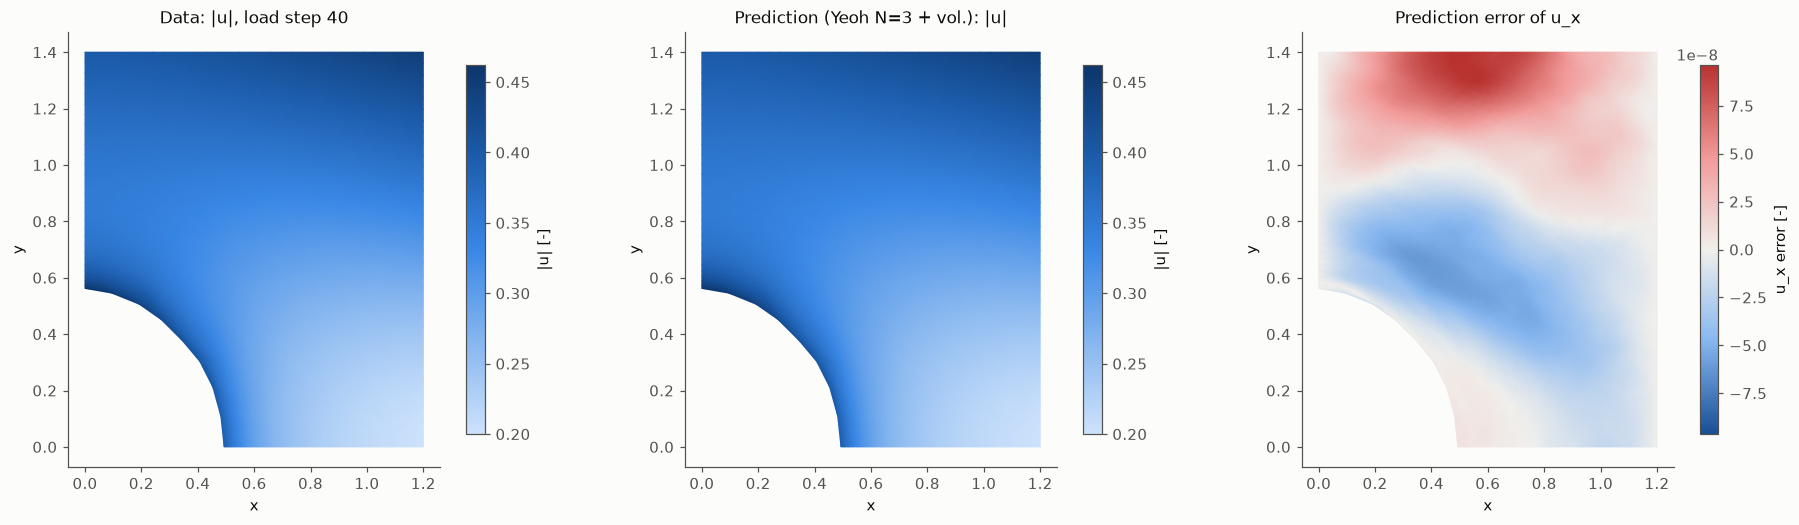

In [25]:
last_step = field_steps[-1]
predicted = field_solutions["yeoh3_compressible"][-1].displacement
figure, axes = plt.subplots(1, 3, figsize=(17, 4.8))
plotting.plot_nodal_field(last_step, np.linalg.norm(last_step.displacement, axis=1), axes[0], "Data: |u|, load step 40", "|u| [-]")
plotting.plot_nodal_field(last_step, np.linalg.norm(predicted, axis=1), axes[1], "Prediction (Yeoh N=3 + vol.): |u|", "|u| [-]")
plotting.plot_nodal_field(
    last_step,
    predicted[:, 0] - last_step.displacement[:, 0],
    axes[2],
    "Prediction error of u_x",
    "u_x error [-]",
    diverging=True,
)
figure.tight_layout()
plotting.save_figure(figure, "source3_prediction", FIGURES)
plt.show()

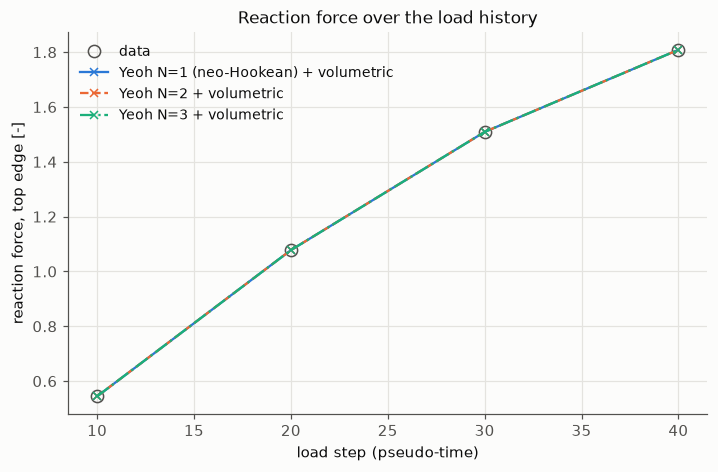

In [26]:
TOP_EDGE_GROUP = 4
figure, ax = plt.subplots(figsize=(7.5, 4.5))
plotting.plot_reactions(
    [step.load_step for step in field_steps],
    [step.reactions[TOP_EDGE_GROUP - 1] for step in field_steps],
    experiment.reaction_predictions(
        FIELD_VARIANTS, field_results, field_steps, field_solutions, TOP_EDGE_GROUP
    ),
    ax,
)
plotting.save_figure(figure, "source3_reactions", FIGURES)
plt.show()

The forward solver reproduces the measured displacement field with a relative error below $6 \cdot 10^{-7}$ at every load step, for every variant.
The reaction force error stays below $3 \cdot 10^{-7}$.
The test load steps 30 and 40 lie beyond the training steps, and their errors are as small as the training errors.
The remaining error is the solver tolerance. The error map shows no concentration at the hole edge, where the strain is largest.

## References

**Data**
1. Marechal, L., Balland, P., Lindenroth, L., Petrou, F., Kontovounisios, C., Bello, F. (2021). Toward a common framework and database of materials for soft robotics. *Soft Robotics*, 8(3), 284–297. Data: https://github.com/LucMarechal/Soft-Robotics-Materials-Database
2. Treloar, L. R. G. (1944). Stress-strain data for vulcanised rubber under various types of deformation. *Transactions of the Faraday Society*, 40, 59–70. Digital copy: Linka, K., Kuhl, E. (2023), *CMAME* 403, 115731, https://github.com/LivingMatterLab/CANN
3. Flaschel, M., Kumar, S., De Lorenzis, L. (2021). Unsupervised discovery of interpretable hyperelastic constitutive laws. *CMAME*, 381, 113852. Data: https://github.com/EUCLID-code/EUCLID-hyperelasticity

**Models and methods**

4. Yeoh, O. H. (1993). Some forms of the strain energy function for rubber. *Rubber Chemistry and Technology*, 66(5), 754–771.
5. Ogden, R. W. (1972). Large deformation isotropic elasticity. *Proceedings of the Royal Society A*, 326, 565–584.
6. Hansen, N. (2016). The CMA evolution strategy: a tutorial. arXiv:1604.00772.
7. Zhang, K., Shasha, D. (1989). Simple fast algorithms for the editing distance between trees and related problems. *SIAM Journal on Computing*, 18(6), 1245–1262.
8. Abbasi, A. et al. (2026). Discovery of hyperelastic constitutive laws from experimental data with EUCLID. *Experimental Mechanics*. (Field data not reachable at the time of writing.)